# De las trayectorias macro a las tasas de pérdida: trayectorias de escenario, satélites y una severidad t asimétrica

**Pregunta:** ¿Qué necesita una trayectoria macro publicada antes de que los satélites de Banco Andino puedan leerla, y cuánto
más alta llega la tasa de pérdida de tarjetas de crédito bajo los escenarios de la Reserva Federal, la EBA y la NGFS que en el
escenario base?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema; los notebooks 02 y 03 no hacen falta
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- decir de qué se compone una prueba de estrés macro (una trayectoria de escenario, modelos satélite y un motor de capital) y
  cuáles de esas tres partes cubre este notebook;
- leer la añada y el proveedor de cada uno de los cuatro escenarios del caso y ver al motor rechazar una trayectoria
  publicada después de la fecha de observación;
- trasladar una trayectoria publicada al punto de partida del banco: la de la Reserva Federal tal cual, la anual de la EBA
  convertida a trimestres, y la de desviaciones de la NGFS sumada a su base, cada una con las funciones de trayectoria del
  motor;
- leer una regresión satélite, proyectarla bajo un escenario a mano para un trimestre y con `project_scenario` para doce, y
  obtener las tasas de pérdida y la pérdida de crédito de cada año;
- ejecutar la mecánica de otras dos herramientas de escenario del motor, el pronóstico condicional con VAR y el ajuste t
  asimétrica de Azzalini-Capitanio del crecimiento en riesgo, y decir qué necesita cada una que los archivos versionados no
  tienen.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lector de los documentos versionados (tres carpetas bajo la raíz del repositorio)
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.stress import paths, satellites, scenario_models

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este notebook lee el lado de escenarios de **C18** (Banco Andino): cuatro variantes de escenario y el documento de modelos de los satélites.

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** los cuatro documentos de variante `data/derived/C18/baseline.json` y `fed-2026-severely-adverse.json` (Reserva Federal 2026, trimestral), `eba-2025-adverse.json` (EBA y ESRB 2025, anual, filas de Estados Unidos) y `ngfs-delayed-transition.json` (NGFS Fase V, desviaciones de NiGEM respecto de la corrida base, anual), y el documento de modelos `data/derived/C18/models-banco-andino.json` (los satélites ajustados: coeficientes, errores estándar, ventanas de muestra). El `outputs.scenario` de cada variante tiene la trayectoria publicada, su traslado y su añada; `outputs.satellites` las tasas proyectadas; `outputs.losses` la pérdida de crédito por año; `outputs.backcast` las tasas realizadas de 2020 a 2025.
- **Lo que no está versionado:** la historia de la Reserva Federal de 1985 a 2019 y las series de castigos con que se ajustaron los satélites. El paso 5 por lo tanto **proyecta** los satélites ajustados con los coeficientes versionados, pero no puede **reajustarlos**; el ajuste es `fit_satellite`, que corre el flujo de generación sobre los archivos crudos.
- **La adaptación, declarada.** Las trayectorias son de Estados Unidos y de la zona euro; Banco Andino es chileno y sintético. Cada trayectoria se traslada al valor de partida propio del banco y los satélites se ajustan sobre tasas de castigo de Estados Unidos, así que toda tasa de pérdida de este notebook lleva en los documentos el rótulo `us-calibrated-adaptation`. Enseña la maquinaria, no un pronóstico para Chile.

In [2]:
# Las cuatro variantes de escenario, el documento de modelos de los satélites y un selector de una trayectoria
VARIANTS = {"baseline": "baseline", "eba": "eba-2025-adverse", "fed": "fed-2026-severely-adverse",
            "ngfs": "ngfs-delayed-transition"}
docs = {key: read_json(f"C18/{name}.json") for key, name in VARIANTS.items()}
models = read_json("C18/models-banco-andino.json")["fit"]
AS_OF = docs["baseline"]["outputs"]["bank"]["as_of"]
SCENARIO = {"baseline": "Fed base", "eba": "EBA 2025 adverso",
            "fed": "Fed 2026 severamente adverso", "ngfs": "NGFS transición tardía"}
LOAN = {"commercial-industrial": "comercial e industrial",
        "commercial-real-estate": "inmobiliario comercial",
        "residential": "hipotecas residenciales", "credit-cards": "tarjetas de crédito",
        "other-consumer": "otro consumo"}
quarters = np.arange(1, 13)


def path_of(key, regressor):
    return next(p for p in docs[key]["outputs"]["scenario"]["paths"] if p["maps_to_regressor"] == regressor)

## Método

### Paso 1: los escenarios y su añada

Una prueba de estrés macro tiene tres capas (dossier 05, H.1): un **generador de escenarios** de trayectorias macrofinancieras a un horizonte de dos a tres años, **modelos satélite** que llevan las trayectorias a parámetros de riesgo, y un **motor de capital** que convierte pérdidas e ingresos en razones de capital (notebook 05). Este notebook cubre las dos primeras.

Cada escenario es un documento publicado con una fecha, su **añada**. Un escenario publicado después de la fecha en que se observa un modelo dejaría entrar el futuro en la validación, así que `check_vintage` del motor rechaza una trayectoria cuya añada es posterior a la fecha de observación y acepta fechas iguales.

La celda siguiente comprueba la añada de cada escenario contra la fecha de observación del banco con `check_vintage`, imprime
proveedor, añada y las variables que aporta cada escenario, y luego ofrece al motor una trayectoria con fecha un mes posterior
a la observación.

In [3]:
# Comprobar la añada de cada escenario con el motor y mostrar el rechazo de una trayectoria publicada tras la
# observación
for key, doc in docs.items():
    scenario = doc["outputs"]["scenario"]
    paths.check_vintage(scenario["vintage_date"], AS_OF)
    variables = [p["maps_to_regressor"] for p in scenario["paths"]]
    print(f"{SCENARIO[key]:30s} {scenario['provider']:9s} {scenario['vintage_date']}  {variables}")
print("fecha de observación del banco", AS_OF)
try:
    paths.check_vintage("2026-09-30", AS_OF)
except ValueError:
    print("una trayectoria con fecha 2026-09-30 es rechazada")

Fed base                       fed       2026-02-04  ['unemployment_rate', 'real_gdp_growth', 'prime_rate']
EBA 2025 adverso               eba-esrb  2025-02-26  ['real_gdp_growth', 'unemployment_rate', 'treasury_10y']
Fed 2026 severamente adverso   fed       2026-02-04  ['unemployment_rate', 'real_gdp_growth', 'prime_rate']
NGFS transición tardía         ngfs      2024-11-01  ['unemployment_rate', 'prime_rate', 'treasury_10y', 'real_gdp_growth']
fecha de observación del banco 2026-08-31
una trayectoria con fecha 2026-09-30 es rechazada


### Paso 2: la forma de una trayectoria sobre el punto de partida del banco

Los satélites parten del último trimestre observado del banco, 2025 T4, no de la fecha de partida propia del escenario. El motor por lo tanto **traslada** una trayectoria publicada al destino: se conserva la forma de la trayectoria, su cambio desde su punto de partida propio, y se suma al último valor observado del banco (decisión Q6 del caso),

$$\tilde x_t = x^{\text{destino}}_{0} + \left(x_t - x^{\text{origen}}_{0}\right), \qquad t = 1, \dots, 12,$$

que implementa `transpose_path(levels, source_jump_off, target_value, n)`. Para los escenarios de la Reserva Federal el punto de partida de origen es 2025 T4 y el destino es el mismo trimestre, de modo que el traslado no cambia nada: la primera prueba de la maquinaria es que devuelva la trayectoria publicada.

La celda siguiente toma la tasa de desempleo del escenario severamente adverso, llama a `transpose_path` con el punto de
partida de origen y el valor del banco, y dibuja los trimestres publicados, la trayectoria trasladada y la versionada.

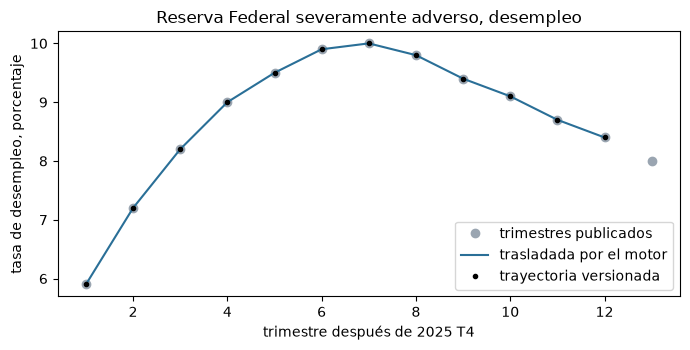

punto de partida de origen y valor del banco 4.5 4.5
trimestres publicados [ 5.9  7.2  8.2  9.   9.5  9.9 10.   9.8  9.4  9.1  8.7  8.4  8. ]


In [4]:
# Trasladar la trayectoria de desempleo severamente adversa de la Reserva Federal y dibujarla contra la
# versionada
unemployment = path_of("fed", "unemployment_rate")
published = np.array([row["value"] for row in unemployment["levels"]])
jump = unemployment["transposition"]["source_jump_off"]["value"]
target = unemployment["transposition"]["target"]["value"]
transposed = paths.transpose_path(published, jump, target, 12)
baked = np.array([row["value"] for row in unemployment["transposed"]])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, 14), published, "o", color="#9aa5b1", label="trimestres publicados")
ax.plot(quarters, transposed, color="#2a6f97", label="trasladada por el motor")
ax.plot(quarters, baked, "k.", label="trayectoria versionada")
ax.set_xlabel("trimestre después de 2025 T4")
ax.set_ylabel("tasa de desempleo, porcentaje")
ax.set_title("Reserva Federal severamente adverso, desempleo")
ax.legend()
fig.tight_layout()
plt.show()
print("punto de partida de origen y valor del banco", jump, target)
print("trimestres publicados", published)

Las tres series quedan una sobre otra: la trayectoria de la Reserva Federal parte del mismo trimestre, 2025 T4, que el banco,
de modo que el punto de partida de origen y el valor del banco son ambos 4,5 por ciento y el traslado deja la trayectoria
como está. El desempleo sube de 5,9 por ciento en el primer trimestre a un máximo de 10,0 en el séptimo y baja a 8,4 en el
duodécimo. Un traslado que no cambia nada es la primera prueba de la maquinaria, y los dos proveedores siguientes, cuyos
puntos de partida no coinciden con el del banco, son donde se justifica.

### Paso 3: la trayectoria de la EBA, de anual a trimestral

La EBA y la ESRB publican niveles anuales solo para 2025, 2026 y 2027. Los satélites son trimestrales, así que `annual_to_quarterly(year_end_levels, jump_off_level)` une los niveles de fin de año linealmente desde el nivel de partida: el trimestre $k$ de un año es $\text{prev} + (\text{cur} - \text{prev})\,k/4$, y el cuarto trimestre es el nivel de fin de año mismo. Si los valores del libro son promedios anuales o valores de fin de año es NO VERIFICADO en el registro de la investigación, y el motor los trata como niveles de fin de año. El punto de partida del escenario de la EBA es 2024 T4 (el año base del ejercicio), mientras que el del banco es 2025 T4, así que ahora el traslado importa: la forma se conserva y se suma al valor de 2025 T4 del banco.

La celda siguiente convierte los niveles de fin de año de la EBA de desempleo y crecimiento del PIB a trimestres con
`annual_to_quarterly`, los traslada con `transpose_path` y dibuja las tres etapas: los niveles de fin de año, la unión
trimestral y la trayectoria trasladada.

unemployment_rate niveles de fin de año [ 8.914 10.046  8.647]
punto de partida y valor del banco 4.081 4.5
desplazamiento de la trayectoria 0.42
real_gdp_growth niveles de fin de año [-5.055 -2.454  4.28 ]
punto de partida y valor del banco 2.765 1.0
desplazamiento de la trayectoria -1.76


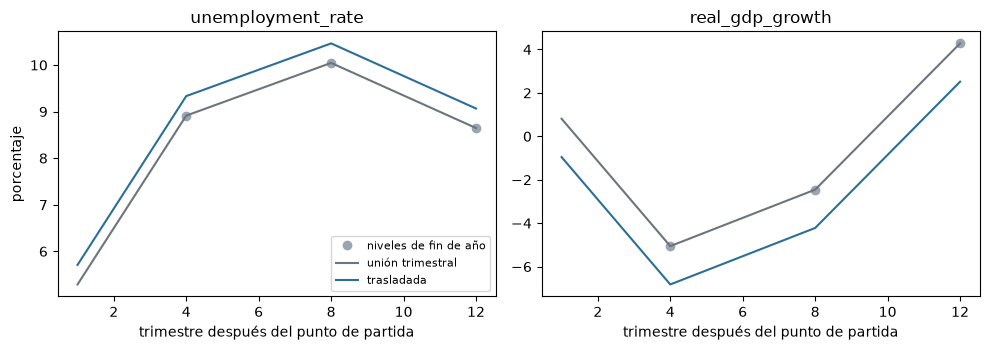

In [5]:
# Convertir los niveles anuales de la EBA a trimestres, trasladarlos al punto de partida del banco y dibujar las
# tres etapas
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, regressor in zip(axes, ("unemployment_rate", "real_gdp_growth")):
    p = path_of("eba", regressor)
    year_end = np.array([row["value"] for row in p["levels"]])
    source_jump = p["transposition"]["source_jump_off"]["value"]
    bank_value = p["transposition"]["target"]["value"]
    quarterly = paths.annual_to_quarterly(year_end, source_jump)
    moved = paths.transpose_path(quarterly, source_jump, bank_value, 12)
    ax.plot(quarters[3::4], year_end, "o", color="#9aa5b1", label="niveles de fin de año")
    ax.plot(quarters, quarterly, color="#6c757d", label="unión trimestral")
    ax.plot(quarters, moved, color="#2a6f97", label="trasladada")
    ax.set_title(regressor)
    ax.set_xlabel("trimestre después del punto de partida")
    print(regressor, "niveles de fin de año", np.round(year_end, 3))
    print("punto de partida y valor del banco", round(source_jump, 3), bank_value)
    print("desplazamiento de la trayectoria", round(bank_value - source_jump, 2))
axes[0].set_ylabel("porcentaje")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

La EBA publica tres niveles anuales, así que los puntos son 8,91; 10,05 y 8,65 por ciento de desempleo a fines de 2025, 2026 y
2027; la línea gris los une linealmente desde el punto de partida del ejercicio en 4,08, y la línea azul es la misma forma
subida 0,42 puntos porque el punto de partida del banco es 4,5. El crecimiento va al revés, 1,76 puntos hacia abajo, porque el
banco parte de 1,0 por ciento frente a 2,77 de la EBA. El traslado conserva la forma del choque y reemplaza el punto de
partida, que es la elección que hizo el caso (decisión Q6); supone que el banco sentiría el cambio de la EBA y no su nivel.

### Paso 4: la trayectoria de la NGFS, una desviación de una corrida base

Las corridas de la NGFS Fase V publican, para cada escenario, la **desviación** respecto de la corrida Base, así que el nivel de un escenario es el nivel base más la desviación (una diferencia porcentual para el PIB): `level_from_deviation(baseline, deviation, kind)` con `kind` igual a `plus` o `percent`. El choque de política de la transición tardía actúa en **2031 a 2033** en las corridas de la NGFS, así que el caso toma esos tres años y los traslada al punto de partida de 2025 T4 del banco: la forma del choque, no su calendario.

La celda siguiente reconstruye los niveles de desempleo y de tasa de política de la NGFS como la corrida base más la desviación
con `level_from_deviation`, los convierte a trimestres y los traslada, y dibuja la corrida base, los niveles reconstruidos y la
trayectoria trasladada.

Una trayectoria publicada termina en un horizonte, y los satélites pueden necesitar más trimestres.
`revert_to_baseline(path, baseline_tail, n, reversion_quarters)` extiende una trayectoria más allá de su final llevándola
linealmente de vuelta a la cola de la base en `reversion_quarters` pasos (una convención del caso, 12). La celda posterior a la
figura extiende a 24 trimestres la trayectoria de desempleo severamente adversa del paso 2, que el horizonte versionado de 12
trimestres no usa.

unemployment_rate corrida base [4.442 4.494 4.537] desviación [0.106 0.408 0.324]
prime_rate corrida base [3.25 3.25 3.25] desviación [ 0.03  -0.57  -0.603]


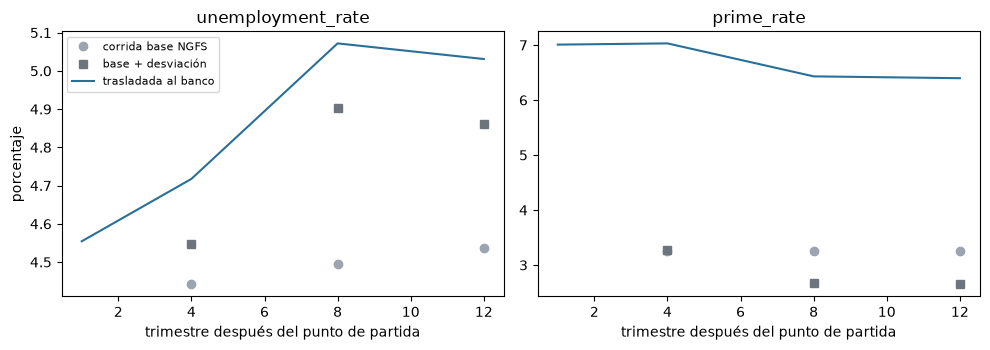

ventana del choque de política 2031 2033


In [6]:
# Reconstruir los niveles de la NGFS como base + desviación, convertir, trasladar y dibujar las etapas
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, regressor in zip(axes, ("unemployment_rate", "prime_rate")):
    p = path_of("ngfs", regressor)
    baseline_run = np.array([row["value"] for row in p["level_rule"]["baseline"]])
    deviation = np.array([row["value"] for row in p["source"]])
    rebuilt = paths.level_from_deviation(baseline_run, deviation, "plus")
    source_jump = p["transposition"]["source_jump_off"]["value"]
    bank_value = p["transposition"]["target"]["value"]
    moved = paths.transpose_path(paths.annual_to_quarterly(rebuilt, source_jump), source_jump, bank_value, 12)
    ax.plot(quarters[3::4], baseline_run, "o", color="#9aa5b1", label="corrida base NGFS")
    ax.plot(quarters[3::4], rebuilt, "s", color="#6c757d", label="base + desviación")
    ax.plot(quarters, moved, color="#2a6f97", label="trasladada al banco")
    ax.set_title(regressor)
    ax.set_xlabel("trimestre después del punto de partida")
    print(regressor, "corrida base", np.round(baseline_run, 3), "desviación", np.round(deviation, 3))
axes[0].set_ylabel("porcentaje")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
window = docs["ngfs"]["outputs"]["scenario"]["policy_shock_window"]
print("ventana del choque de política", window["start_year"], window["end_year"])

La NGFS no publica un nivel sino una desviación respecto de su corrida base, así que los niveles de desempleo son 4,547; 4,902 y
4,861 por ciento para los tres años del choque, 0,11; 0,41 y 0,32 puntos sobre una base de cerca de 4,5, y la tasa de política
baja de 0,57 a 0,60 puntos. El choque es pequeño comparado con el de la Reserva Federal, y por eso este escenario quedará cerca
de la base en los Resultados. El caso toma la ventana de 2031 a 2033 del choque de política y la lleva al punto de partida de
2025 T4 del banco, conservando la forma del choque y no su calendario.

La celda siguiente extiende la trayectoria de desempleo severamente adversa de la Reserva Federal del paso 2 de 12 a 24
trimestres con `revert_to_baseline`, llevándola de vuelta hacia la cola de la base en 12 pasos, y dibuja la extensión.

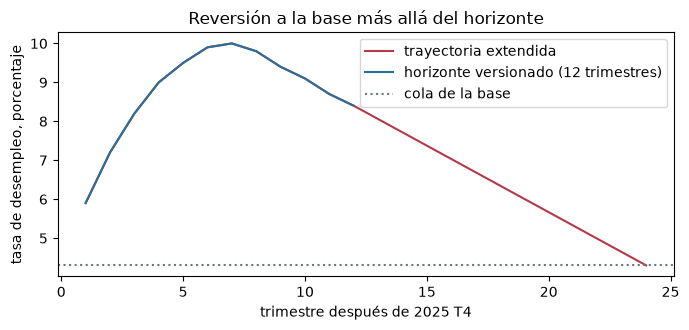

cola de la base 4.3 últimos trimestres [5.32 4.98 4.64 4.3 ]


In [7]:
# Extender la trayectoria de desempleo severamente adversa a 24 trimestres volviendo a la cola de la base
baseline_tail = path_of("baseline", "unemployment_rate")["transposed"][-1]["value"]
extended = paths.revert_to_baseline(transposed, baseline_tail, 24, 12)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(1, 25), extended, color="#b23a48", label="trayectoria extendida")
ax.plot(quarters, transposed, color="#2a6f97", label="horizonte versionado (12 trimestres)")
ax.axhline(baseline_tail, color="#6c757d", linestyle=":", label="cola de la base")
ax.set_xlabel("trimestre después de 2025 T4")
ax.set_ylabel("tasa de desempleo, porcentaje")
ax.set_title("Reversión a la base más allá del horizonte")
ax.legend()
fig.tight_layout()
plt.show()
print("cola de la base", baseline_tail, "últimos trimestres", np.round(extended[-4:], 2))

Después del duodécimo trimestre, donde la trayectoria publicada termina en 8,4 por ciento, la extensión vuelve en línea recta y
alcanza la cola de la base de 4,3 por ciento doce trimestres más tarde. La línea recta es una convención del caso y no una
estimación de cómo se recupera el desempleo, y solo importa para un satélite que necesite más de los doce trimestres que usa
el horizonte versionado, lo que no ocurre con ninguno de los cinco satélites del caso. Se muestra porque una trayectoria que se
corta de golpe se leería, si no, como una que se queda en su último valor.

### Paso 5: un satélite, a mano y con el motor

Un satélite explica la tasa de pérdida $DR_t$ de un tipo de préstamo por las variables macro, a través de un enlace $g$ (dossier 04, I.1 y dossier 05, H.1 capa 2):

$$g(DR_t) = \alpha + \sum_{k=1}^{p}\phi_k\, g(DR_{t-k}) + \sum_{j,\ell}\beta_{j\ell}\, X_{j,t-\ell} + \varepsilon_t.$$

Con el enlace **probit**, $g = \Phi^{-1}$, la regresión es una regresión del ciclo crediticio latente del modelo de un factor de Vasicek sobre las variables macro, razón por la cual el enlace es consistente con los modelos de cartera del tema 06. Los segmentos cuya tasa es cero o negativa en algunos trimestres (recuperaciones netas de bienes raíces) usan el enlace identidad. En el caso $p = 1$, los regresores son el crecimiento del PIB real y la tasa de desempleo con rezagos 0 y 1, y cada satélite se ajusta por mínimos cuadrados ordinarios sobre 1985 a 2019 (1991 a 2019 para los dos tipos de bienes raíces).

La celda siguiente lee los coeficientes versionados del satélite comercial e industrial, toma la última tasa realizada (2025 T4, del bloque de retroproyección) y calcula **el primer trimestre proyectado a mano**: el enlace de la última tasa, cada término de la ecuación, la suma y el enlace inverso. Luego llama a `project_scenario` para los doce trimestres y para los cinco tipos de préstamo bajo el escenario severamente adverso de la Reserva Federal, y compara con las tasas versionadas.

In [8]:
# Los regresores severamente adversos de la Reserva Federal, las últimas tasas realizadas y las tasas
# proyectadas versionadas
REGRESSORS = ("real_gdp_growth", "unemployment_rate")
fed_paths = {p["maps_to_regressor"]: p for p in docs["fed"]["outputs"]["scenario"]["paths"]}
X = np.column_stack([[row["value"] for row in fed_paths[name]["transposed"]] for name in REGRESSORS])
jump_off = np.array([[fed_paths[name]["transposition"]["target"]["value"] for name in REGRESSORS]])
backcast = docs["fed"]["outputs"]["backcast"]["per_loan_type"]
last_rate = {b["fed_loan_type"]: b["quarters"][-1]["realised"] for b in backcast}
fed_types = docs["fed"]["outputs"]["satellites"]["fed_loan_types"]
committed_rates = {t["fed_loan_type"]: np.array([q["rate"] for q in t["quarters"]]) for t in fed_types}
ci = next(m for m in models["satellites"] if m["fed_loan_type"] == "commercial-industrial")
coef = {c["name"]: c["estimate"] for c in ci["coefficients"]}

La celda siguiente calcula a mano el primer trimestre proyectado del satélite comercial e industrial: el vínculo probit de la
última tasa realizada, cada término de la ecuación, su suma y el vínculo inverso, con `link` e `inverse_link` del motor. Las
barras muestran los seis términos en la escala del vínculo.

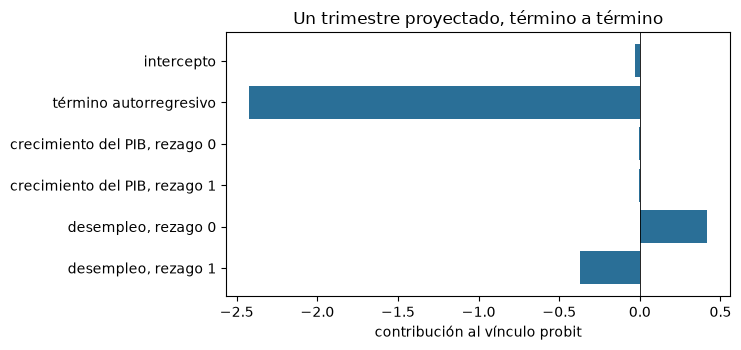

última tasa realizada y su vínculo 0.005600000000000001 -2.5364
suma de los términos y tasa proyectada -2.4138 0.007894


In [9]:
# El primer trimestre proyectado del satélite comercial e industrial a mano, término a término
g0 = satellites.link("probit", np.array([last_rate["commercial-industrial"]]))[0]
terms = {"intercepto": coef["intercept"],
         "término autorregresivo": coef["ar_1"] * g0,
         "crecimiento del PIB, rezago 0": coef["real_gdp_growth_lag0"] * X[0, 0],
         "crecimiento del PIB, rezago 1": coef["real_gdp_growth_lag1"] * jump_off[0, 0],
         "desempleo, rezago 0": coef["unemployment_rate_lag0"] * X[0, 1],
         "desempleo, rezago 1": coef["unemployment_rate_lag1"] * jump_off[0, 1]}
link_value = sum(terms.values())
rate = float(satellites.inverse_link("probit", np.array([link_value]))[0])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(list(terms)[::-1], list(terms.values())[::-1], color="#2a6f97")
ax.axvline(0, color="black", linewidth=0.6)
ax.set_xlabel("contribución al vínculo probit")
ax.set_title("Un trimestre proyectado, término a término")
fig.tight_layout()
plt.show()
print("última tasa realizada y su vínculo", last_rate["commercial-industrial"], round(float(g0), 4))
print("suma de los términos y tasa proyectada", round(link_value, 4), round(rate, 6))

Cinco de los seis términos son pequeños. El término autorregresivo, menos 2,42, es el valor del vínculo de la tasa del
trimestre anterior y domina, así que la tasa de pérdida es sobre todo persistencia; las variables macro la mueven en el margen,
el desempleo sumando 0,42 en el trimestre actual y quitando 0,37 por su rezago. La suma, menos 2,41, pasa por el vínculo
inverso a una tasa de 0,007894 en el primer trimestre, desde 0,0056 realizada. Un satélite no es más que esta ecuación, y por
eso puede proyectarse con coeficientes versionados sin reajustarlo.

La celda siguiente reconstruye un `SatelliteFit` del motor desde los coeficientes versionados de cada uno de los cinco
satélites; ese pequeño adaptador solo traspasa las claves del documento al constructor del motor.

In [10]:
# Reconstruir el SatelliteFit del motor de cada tipo de crédito desde los coeficientes versionados
def satellite_fit(model):
    names = list(dict.fromkeys(r["name"] for r in model["regressors"]))
    coefficients = model["coefficients"]
    return satellites.SatelliteFit(
        link=model["link"], window_start=model["sample_window"]["start"], window_end=model["sample_window"]["end"],
        n_obs=model["n_obs"], ar_order=model["ar_order"], regressor_names=tuple(names),
        lags=tuple(sorted({r["lag"] for r in model["regressors"]})),
        coefficient_names=tuple(c["name"] for c in coefficients),
        estimates=tuple(c["estimate"] for c in coefficients),
        std_errors=tuple(c["std_error"] for c in coefficients), r_squared=model["fit_statistics"]["r_squared"],
        residual_sd=model["fit_statistics"]["residual_sd"])


fits = {m["fed_loan_type"]: satellite_fit(m) for m in models["satellites"]}
for loan_type, fit in fits.items():
    print(f"{LOAN[loan_type]:26s} {fit.link:8s} n_obs {fit.n_obs:3d}  R2 {fit.r_squared:.3f}")

comercial e industrial     probit   n_obs 139  R2 0.942
inmobiliario comercial     identity n_obs 115  R2 0.959
hipotecas residenciales    identity n_obs 115  R2 0.954
tarjetas de crédito        probit   n_obs 139  R2 0.926
otro consumo               probit   n_obs 139  R2 0.910


La celda siguiente llama a `project_scenario` para los doce trimestres del escenario severamente adverso de cada uno de los
cinco tipos de crédito y dibuja las tasas proyectadas. También imprime la mayor brecha entre cada proyección y las tasas
versionadas, la única verificación de reproducción de este notebook.

comercial e industrial     tasa máxima 0.0180  brecha 0.0e+00
inmobiliario comercial     tasa máxima 0.0179  brecha 0.0e+00
hipotecas residenciales    tasa máxima 0.0114  brecha 0.0e+00
tarjetas de crédito        tasa máxima 0.0873  brecha 0.0e+00
otro consumo               tasa máxima 0.0206  brecha 0.0e+00


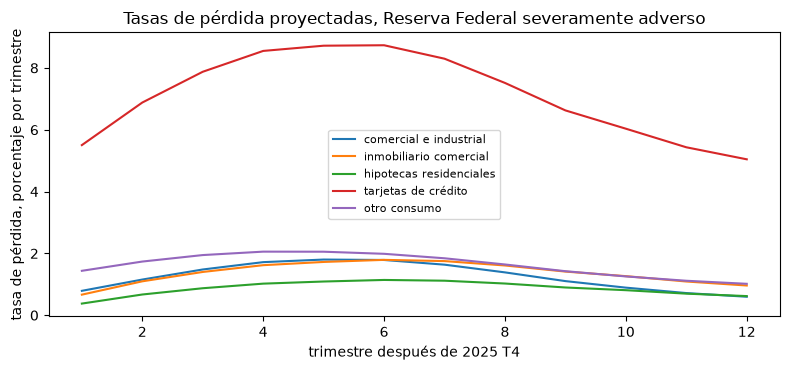

In [11]:
# Proyectar los cinco satélites bajo el escenario severamente adverso y dibujar las tasas
fig, ax = plt.subplots(figsize=(8, 3.8))
for loan_type, fit in fits.items():
    start = satellites.link(fit.link, np.array([last_rate[loan_type]]))
    projection = satellites.project_scenario(fit, start, jump_off, X)
    ax.plot(quarters, projection.rates * 100, label=LOAN[loan_type])
    gap = float(np.max(np.abs(projection.rates - committed_rates[loan_type])))
    print(f"{LOAN[loan_type]:26s} tasa máxima {projection.rates.max():.4f}  brecha {gap:.1e}")
ax.set_xlabel("trimestre después de 2025 T4")
ax.set_ylabel("tasa de pérdida, porcentaje por trimestre")
ax.set_title("Tasas de pérdida proyectadas, Reserva Federal severamente adverso")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Todos los satélites suben en el primer año y luego ceden cuando el desempleo gira, con la tasa de tarjetas de crédito muy por
encima del resto, en un máximo de 8,73 por ciento al trimestre, y las hipotecas residenciales al fondo con 1,14. La brecha
impresa con las tasas versionadas es cero para los cinco, lo que significa que el archivo versionado es exactamente lo que da
el motor con sus coeficientes y trayectoria; la brecha se imprime una vez aquí y el resto del notebook se apoya en ella. Los
cinco satélites tienen un $R^2$ entre 0,910 y 0,959 en 115 a 139 trimestres, dentro de la muestra, así que son proyecciones de
una relación ajustada y no pronósticos fuera de muestra.

**De los tipos de crédito a la pérdida de crédito del banco.** La cartera de Banco Andino está en tres clases, cada una
asignada a tipos de crédito de la Reserva Federal con pesos fijos (una adaptación del caso): comercial = 0,6 C&I + 0,4
inmobiliario comercial, consumo = 0,5 tarjetas + 0,5 otro consumo, hipotecario = residencial. La pérdida de crédito de un año
es la exposición de cada clase por la media de las cuatro tasas trimestrales del año, sumada sobre las clases. La celda
siguiente construye las tasas por clase con los pesos y dibuja la pérdida de crédito anual de cada clase.

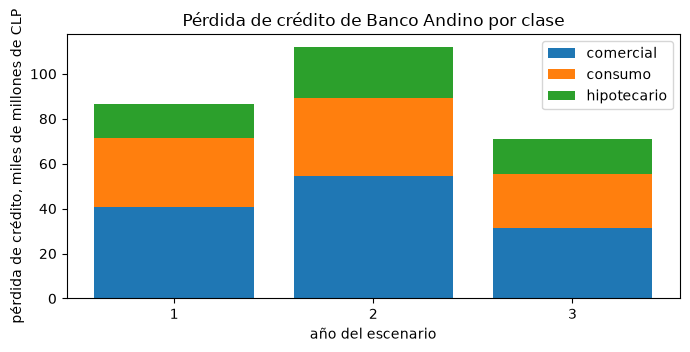

pérdida de crédito por año, millones de CLP [ 86518.6 111986.8  71005.1]
versionada [86518.6, 111986.8, 71005.1]


In [12]:
# Tasas por clase desde los pesos de los tipos de crédito y la exposición, luego la pérdida de crédito de cada
# año por clase
classes = docs["fed"]["outputs"]["satellites"]["banco_andino_classes"]
CLASS = {"commercial": "comercial", "consumer": "consumo", "mortgage": "hipotecario"}
yearly = {}
for klass in classes:
    class_rate = sum(w * committed_rates[t] for t, w in zip(klass["maps_from"], klass["weights"]))
    yearly[klass["banco_andino_class"]] = class_rate.reshape(3, 4).mean(axis=1) * klass["exposure_clp_m"] / 1e3
fig, ax = plt.subplots(figsize=(7, 3.6))
bottom = np.zeros(3)
for name, values in yearly.items():
    ax.bar(["1", "2", "3"], values, bottom=bottom, label=CLASS[name])
    bottom += values
ax.set_xlabel("año del escenario")
ax.set_ylabel("pérdida de crédito, miles de millones de CLP")
ax.set_title("Pérdida de crédito de Banco Andino por clase")
ax.legend()
fig.tight_layout()
plt.show()
print("pérdida de crédito por año, millones de CLP", np.round(bottom * 1e3, 1))
print("versionada", [round(row["credit"], 1) for row in docs["fed"]["outputs"]["losses"]["scenario_losses"]])

La cartera comercial es la clase mayor, con una pérdida de cerca de 40 a 54 mil millones al año, el consumo es menor en
exposición pero pierde casi tanto por año porque sus tasas son las más altas, y las hipotecas aportan de 15 a 23 mil millones.
El total alcanza su máximo en el segundo año, con 111.986,8 millones de pesos, entre 86.518,6 en el primero y 71.005,1 en el
tercero, que es la forma de la trayectoria de desempleo con rezago. Son solo pérdidas de crédito; el plan de capital del
notebook 05 suma los otros riesgos, los ingresos y el balance.

### Paso 6: un VAR y un pronóstico condicional

Los satélites asocian dos variables macro elegidas con tasas de pérdida. Una **autorregresión vectorial** modela varias variables juntas, $y_t = c + \sum_{l=1}^{p} A_l\, y_{t-l} + u_t$ (dossier 05, H.2), y un escenario de estrés es entonces un **pronóstico condicional**: se da la trayectoria de un subconjunto de las variables y las otras se siguen del modelo, con los choques de las variables libres correlacionados con los de las condicionadas. `fit_var(y, lags)` la estima por MCO ecuación por ecuación y `var_conditional_forecast(fit, y_history, path, conditioned)` calcula las trayectorias condicionales (la forma período a período; la forma de horizonte completo de Waggoner y Zha es NO VERIFICADA contra el artículo).

El caso no hornea un VAR, y los archivos versionados no tienen historia macro para ajustar uno. Lo que sí tienen son tasas de castigo trimestrales reales de 2020 a 2025 (las tasas realizadas del bloque de retroproyección), así que la celda siguiente corre la **mecánica** sobre ellas: un VAR(1) de la tasa comercial e industrial y la tasa de tarjetas de crédito (24 trimestres, una muestra corta que solo una demostración puede permitirse), condicionado a que la tasa de tarjetas siga la proyección del satélite bajo el escenario severamente adverso. La salida es lo que haría la tasa C&I si las pérdidas de tarjetas siguieran esa trayectoria, para comparar con la proyección propia del satélite C&I. Es una ilustración de la herramienta, no un hallazgo.

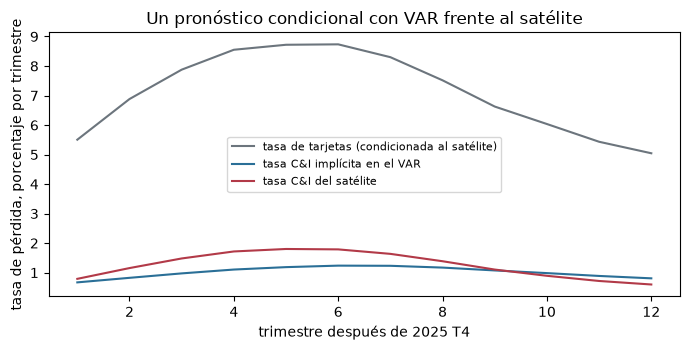

observaciones 24 valores propios de A_1 [0.865+0.128j 0.865-0.128j]


In [13]:
# Un VAR(1) sobre las tasas realizadas C&I y de tarjetas de 2020-2025, condicionado a la trayectoria del
# satélite de tarjetas
realised = {b["fed_loan_type"]: np.array([q["realised"] for q in b["quarters"]]) for b in backcast}
y = np.column_stack([realised["commercial-industrial"], realised["credit-cards"]])
var_fit = scenario_models.fit_var(y, 1)
card_path = committed_rates["credit-cards"].reshape(-1, 1)
conditional = scenario_models.var_conditional_forecast(var_fit, y[-1:], card_path, [1])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(quarters, card_path[:, 0] * 100, color="#6c757d", label="tasa de tarjetas (condicionada al satélite)")
ax.plot(quarters, conditional[:, 0] * 100, color="#2a6f97", label="tasa C&I implícita en el VAR")
ax.plot(quarters, committed_rates["commercial-industrial"] * 100, color="#b23a48", label="tasa C&I del satélite")
ax.set_xlabel("trimestre después de 2025 T4")
ax.set_ylabel("tasa de pérdida, porcentaje por trimestre")
ax.set_title("Un pronóstico condicional con VAR frente al satélite")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("observaciones", y.shape[0], "valores propios de A_1", np.round(np.linalg.eigvals(var_fit.coefficients[0]), 3))

El VAR se ajusta con solo 24 trimestres de tasas realizadas, así que es una demostración de la herramienta y no un hallazgo.
Condicionado a que la tasa de tarjetas siga la trayectoria del satélite, implica una tasa comercial e industrial que sube a
1,24 por ciento al trimestre, mientras que el satélite propio de ese tipo de crédito, ajustado con 139 trimestres y regresores
macro, llega a 1,80. Dos modelos de la misma cantidad, con muestras e información distintas, discrepan en un tercio en el
máximo, que es una razón para mantener un retador junto al campeón y no un resultado sobre ninguno. Los valores propios de la
matriz de coeficientes del VAR quedan dentro del círculo unitario, así que su pronóstico es estable.

### Paso 7: crecimiento en riesgo y la densidad t asimétrica

El **crecimiento en riesgo** (Adrian, Boyarchenko y Giannone 2019) construye toda una distribución predictiva del crecimiento del PIB en dos pasos. El paso 1 corre **regresiones cuantílicas** del crecimiento anualizado promedio sobre una constante, el crecimiento actual y un índice de condiciones financieras, una para cada cuantil de 5, 25, 75 y 95 por ciento. El paso 2 ajusta la densidad **t asimétrica de Azzalini y Capitanio**

$$f(y;\mu,\sigma,\alpha,\nu) = \frac{2}{\sigma}\, t\!\left(\frac{y-\mu}{\sigma};\nu\right) T\!\left(\alpha\,\frac{y-\mu}{\sigma}\sqrt{\frac{\nu+1}{\nu+\left(\frac{y-\mu}{\sigma}\right)^2}};\ \nu+1\right)$$

a los cuatro cuantiles estimados por mínimos cuadrados, donde $t$ y $T$ son la densidad y la función de distribución de la t de Student y $\alpha$ la asimetría ($\alpha = 0$ es la t de Student). Los cuantiles inferiores se mueven con fuerza con las condiciones financieras mientras los superiores son estables, lo que hace de la densidad ajustada un **calibrador de severidad** para escenarios.

El motor tiene ambos pasos. `gar_quantile_regressions` necesita `statsmodels` (el extra opcional `stress` del motor) y una serie de condiciones financieras; **ninguno está en el entorno del notebook ni en los archivos versionados**, así que el paso 1 no se corre aquí. El paso 2, `fit_skewed_t_to_quantiles`, solo necesita cuatro cuantiles, y la celda siguiente lo prueba de dos maneras. Primero, la densidad con $\alpha = 0$ debe igualar la t de Student e integrar 1. Segundo, un ajuste de verdad conocida: los cuantiles de una normal con la desviación estándar del crecimiento del PIB real de 1985 a 2019 (el `factor_space` versionado) deben devolver $\alpha \approx 0$ y un $\nu$ grande; luego un conjunto de cuantiles con cola inferior pesada, la forma que encuentra el crecimiento en riesgo en condiciones de estrés (múltiplos ilustrativos de esa desviación estándar), debe devolver un $\alpha$ negativo.

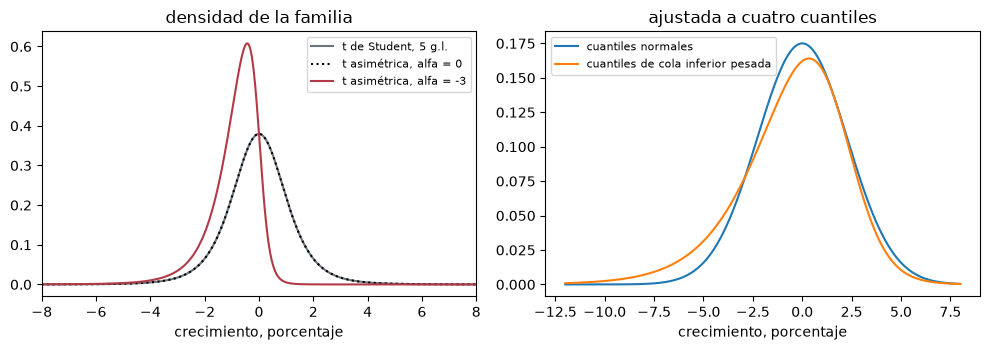

área bajo la densidad con alfa = -3 0.9999
cuantiles normales: alfa, nu, sigma 1.4e-07 1000 2.279
cola inferior pesada: alfa, nu, sigma -1.833 10.2 3.393


In [14]:
# Comprobar la densidad t asimétrica contra la t de Student y ajustarla a una verdad conocida y a cuantiles de
# cola inferior pesada
z = np.linspace(-12, 12, 4001)
skew0 = scenario_models.skewed_t_pdf(z, 0.0, 1.0, 0.0, 5.0)
skew3 = scenario_models.skewed_t_pdf(z, 0.0, 1.0, -3.0, 5.0)
sd_growth = models["factor_space"]["factors"][0]["sd"]
taus = np.array([0.05, 0.25, 0.75, 0.95])
truth = scenario_models.fit_skewed_t_to_quantiles(stats.norm.ppf(taus) * sd_growth)
heavy = scenario_models.fit_skewed_t_to_quantiles(np.array([-2.4, -0.9, 0.6, 1.5]) * sd_growth)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(z, stats.t.pdf(z, 5), color="#6c757d", label="t de Student, 5 g.l.")
axes[0].plot(z, skew0, "k:", label="t asimétrica, alfa = 0")
axes[0].plot(z, skew3, color="#b23a48", label="t asimétrica, alfa = -3")
axes[0].set_xlim(-8, 8)
axes[0].legend(fontsize=8)
grid_y = np.linspace(-12, 8, 400)
pdf_truth = scenario_models.skewed_t_pdf(grid_y, truth.mu, truth.sigma, truth.alpha, truth.nu)
pdf_heavy = scenario_models.skewed_t_pdf(grid_y, heavy.mu, heavy.sigma, heavy.alpha, heavy.nu)
axes[1].plot(grid_y, pdf_truth, label="cuantiles normales")
axes[1].plot(grid_y, pdf_heavy, label="cuantiles de cola inferior pesada")
axes[1].legend(fontsize=8)
for ax, title in zip(axes, ("densidad de la familia", "ajustada a cuatro cuantiles")):
    ax.set_title(title)
    ax.set_xlabel("crecimiento, porcentaje")
fig.tight_layout()
plt.show()
print("área bajo la densidad con alfa = -3", round(float(np.trapezoid(skew3, z)), 4))
print("cuantiles normales: alfa, nu, sigma", f"{truth.alpha:.1e}", round(truth.nu), round(truth.sigma, 3))
print("cola inferior pesada: alfa, nu, sigma", round(heavy.alpha, 3), round(heavy.nu, 2), round(heavy.sigma, 3))

En el panel izquierdo la t asimétrica con alfa cero cae exactamente sobre la t de Student, como debe, y un alfa negativo
traslada la masa a la cola izquierda mientras la densidad sigue integrando 1 (0,9999 en el rango dibujado). En el panel
derecho, cuatro cuantiles normales con la desviación estándar de 2,281 del crecimiento del PIB devuelven un alfa cercano a
cero y un parámetro de grados de libertad en el techo de búsqueda de 1000, que es una normal en el límite; el conjunto de cola
inferior pesada devuelve un alfa de menos 1,833 y 10,2 grados de libertad, una densidad asimétrica a la izquierda. Con cuatro
cuantiles y cuatro parámetros el ajuste es exacto, así que lo que muestra la verificación es que el optimizador recupera una
verdad conocida, no que la forma sea la correcta para un trimestre real.

## Resultados

La última figura pone los cuatro escenarios lado a lado: la trayectoria de desempleo trasladada de cada uno (izquierda) y la
tasa de pérdida de tarjetas de crédito que proyecta el satélite de tarjetas bajo cada uno (derecha). Las trayectorias difieren
en forma y severidad, y el satélite convierte la diferencia en una tasa de pérdida con un rezago y un techo propios.

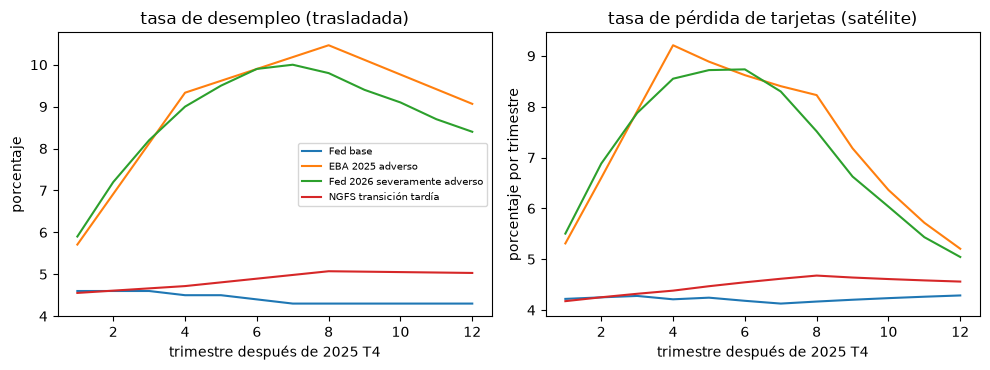

tasa máxima de pérdida de tarjetas por escenario, porcentaje por trimestre {'Fed base': 4.29, 'EBA 2025 adverso': 9.21, 'Fed 2026 severamente adverso': 8.73, 'NGFS transición tardía': 4.68}


In [15]:
# Dibujar las trayectorias de desempleo trasladadas y la tasa de tarjetas que implica cada escenario con el
# satélite
card_fit = fits["credit-cards"]
card_last = satellites.link("probit", np.array([last_rate["credit-cards"]]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
peak = {}
for key in docs:
    p_u, p_g = path_of(key, "unemployment_rate"), path_of(key, "real_gdp_growth")
    u_path = np.array([row["value"] for row in p_u["transposed"]])
    x_path = np.column_stack([[row["value"] for row in p_g["transposed"]], u_path])
    start = np.array([[p_g["transposition"]["target"]["value"], p_u["transposition"]["target"]["value"]]])
    rates = satellites.project_scenario(card_fit, card_last, start, x_path).rates
    peak[SCENARIO[key]] = round(float(rates.max()) * 100, 2)
    axes[0].plot(quarters, u_path, label=SCENARIO[key])
    axes[1].plot(quarters, rates * 100, label=SCENARIO[key])
axes[0].set_title("tasa de desempleo (trasladada)")
axes[0].set_ylabel("porcentaje")
axes[1].set_title("tasa de pérdida de tarjetas (satélite)")
axes[1].set_ylabel("porcentaje por trimestre")
for ax in axes:
    ax.set_xlabel("trimestre después de 2025 T4")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
print("tasa máxima de pérdida de tarjetas por escenario, porcentaje por trimestre", peak)

El orden de la tasa de pérdida de tarjetas sigue a las trayectorias. La base de la Reserva Federal y la transición tardía de
la NGFS se quedan cerca de 4,3 a 4,7 por ciento al trimestre porque sus trayectorias de desempleo son suaves, y los dos
escenarios adversos la duplican. El escenario adverso de la EBA queda algo sobre el severamente adverso de la Reserva Federal,
9,21 contra 8,73 por ciento, porque una vez trasladado al punto de partida del banco su mínimo de crecimiento, menos 6,82 por
ciento, y su máximo de desempleo, 10,47, son más profundos que los de la Reserva Federal. Un escenario es tan severo como su
trayectoria después de moverla al banco, y por eso los pasos 2 a 4 van antes que cualquier satélite.

**Respuesta:** un escenario publicado necesita tres cosas antes de que un satélite pueda leerlo: una añada igual o anterior a la
fecha de observación (2026-08-31, que el motor exige y que todo escenario versionado cumple), un traslado de su forma al punto
de partida del banco (ninguno para la Reserva Federal, una unión lineal de anual a trimestral y un desplazamiento de 0,42
puntos de desempleo para la EBA, base más una desviación para la NGFS) y una trayectoria trimestral de doce trimestres. Con
eso, el satélite de tarjetas proyecta una tasa máxima de pérdida trimestral de 4,29 por ciento en la base de la Reserva
Federal y 4,68 por ciento bajo la transición tardía de la NGFS, contra 8,73 por ciento bajo el escenario severamente adverso de
la Reserva Federal y 9,21 por ciento bajo el adverso de la EBA, y la pérdida de crédito de Banco Andino en el escenario
severamente adverso es de 86.518,6; 111.986,8 y 71.005,1 millones de pesos en sus tres años.

Lo que este notebook no muestra: los satélites se proyectaron y no se reajustaron, porque la historia de 1985 a 2019 no está
versionada; el primer paso de regresiones cuantílicas del crecimiento en riesgo no se ejecutó, porque necesita `statsmodels` y
una serie de condiciones financieras que este entorno no tiene; y ninguna de estas tasas es un pronóstico para Chile, porque
las trayectorias y los coeficientes son de Estados Unidos trasladados a un banco sintético.

## Resumen

- Una prueba de estrés macro tiene tres capas; este notebook cubrió las trayectorias de escenario y los satélites, y el notebook 05 cubre el motor de capital.
- Una trayectoria publicada después de la fecha de observación la rechaza `check_vintage`; toda añada versionada es igual o anterior a ella.
- Una trayectoria publicada se lleva al punto de partida del banco conservando su forma: tal cual para la Reserva Federal, tras unir de anual a trimestral para la EBA, y como base más desviación para la NGFS. El motor reproduce cada trayectoria versionada.
- Un satélite probit es una regresión del ciclo crediticio latente sobre variables macro; con los coeficientes versionados el motor reproduce exactamente las tasas de pérdida versionadas y la pérdida de crédito del banco por año, pero los satélites no pueden reajustarse desde los archivos versionados.
- El pronóstico condicional de un VAR y el ajuste t asimétrico del crecimiento en riesgo son herramientas del motor que el caso no hornea; su mecánica se corrió sobre datos versionados y verdad conocida, y las regresiones cuantílicas del crecimiento en riesgo necesitan `statsmodels` y una serie de condiciones financieras que este entorno no tiene.

**Qué probar a continuación.** Cambia el escenario del paso 5 por el de la EBA y compara las tasas de pérdida máximas de los cinco tipos de préstamo. Luego sigue con el notebook 05, que toma las pérdidas y construye el plan de capital.

## Referencias

- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- NGFS (2024), Escenarios climáticos, Fase V (lanzamiento). https://www.ngfs.net/en/news/ngfs-scenarios-phase-v-launch-event
- Escenarios NGFS Fase V, IIASA Scenario Explorer (las corridas de NiGEM que lee el caso). https://data.ene.iiasa.ac.at/ngfs
- Adrian, T., Boyarchenko, N. y Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Board of Governors of the Federal Reserve System (2026), escenario supervisor severamente adverso 2026, doméstico (el archivo de la trayectoria macro trimestral). https://www.federalreserve.gov/supervisionreg/files/2026_Final_Supervisory_Severely_Adverse_Domestic.csv
- Dossiers 04 (I.1, el satélite y el enlace de Vasicek) y 05 (H.1 y H.2, las tres capas, el VAR y el crecimiento en riesgo) de la investigación persistida de Contraste, resumidos en la base de investigación del SDD.
- Este repositorio: `docs/contracts/engine/stress-api.md` (las funciones de trayectoria, satélite y modelos de escenario).